# MPC — Multimetric

Analisi offline dei risultati in mpc_multimetric_th/results.

Tre simulazioni distinte: multi_space, multi_time e multi_all. Le metriche sono lette dagli archivi, senza dedurle dal nome della cartella. multi_space_errata è esclusa. Modifica RUN_NAMES per lavorare su un solo gruppo.

Le figure usano lo stesso set_style() della reachability: serif, formule Computer Modern, font 14 pt, curve 1.8 pt, sfondo e legenda bianchi. I dati restano quelli salvati: nessuna interpolazione BRT o simulazione MPC viene rilanciata. Le celle di esportazione salvano in grafici/output e sovrascrivono file omonimi. Nella configurazione puoi disattivare EXPORT o cambiare FORMATS e tempi dei frame.

In [1]:
from pathlib import Path
import numpy as np
import sys

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "mpc_utils.py").is_file():
    if (NOTEBOOK_DIR / "grafici/mpc_utils.py").is_file():
        NOTEBOOK_DIR = NOTEBOOK_DIR / "grafici"
    else:
        raise FileNotFoundError("Apri il notebook dalla cartella grafici del repository mpc.")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from plot_utils import set_style
from mpc_utils import (
    repository_root, load_run, run_manifest, compare_scenarios,
    plot_trajectory, plot_trajectories, plot_frames, plot_states, plot_commands,
    plot_values, plot_values_comparison, plot_hj_limits, plot_command_planes,
    plot_costs, cost_consistency, timing_statistics, plot_timings, export_collection,
)

set_style()
ROOT = repository_root(NOTEBOOK_DIR)
EXPORT = True
FORMATS = ("pdf",)  # Anche ("pdf", "eps"). EPS non conserva tutte le trasparenze.
CONTROL_FREQUENCY = 50.0
FRAME_TIMES = (5.0, 7.0, 9.0, 11.0)
VIEW_BEHIND = 10.0
VIEW_AHEAD = 25.0
HJ_STAGE = 0
HJ_SOFTENED = False  # False: vincoli originali senza slack.
PLANE_TIMES = None  # None: tre istanti nell'intervallo HJ attivo.
PER_METRIC_FIGURES = False  # True: aggiunge value e limiti per ciascuna metrica.

figures = {}

def show(name, fig):
    figures[name] = fig
    display(fig)
    plt.close(fig)

RUN_NAMES = ['multi_space', 'multi_time', 'multi_all']
OUTPUT_GROUP = 'multimetric'


## Dati e metriche effettivamente registrate

In [2]:
runs = [load_run(name, ROOT) for name in RUN_NAMES]
display(run_manifest(runs))


,run,metrics,duration_s,dt_s,steps,predictions,costs,recorded_timers
0,multi_space,"euclidean, dce, btn, stn, long_lat",20.0,0.02,1000,True,True,solve_time
1,multi_time,"ttc, time_eggert",20.0,0.02,1000,True,True,solve_time
2,multi_all,"euclidean, dce, btn, stn, long_lat, ttc, time_...",20.0,0.02,1000,True,True,solve_time


## Traiettoria nello spazio

Il colore rappresenta il tempo.

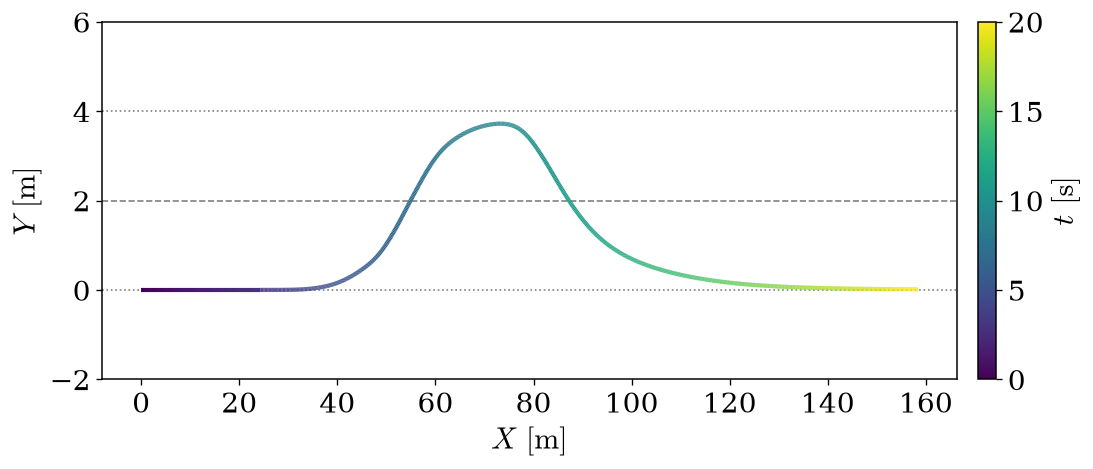

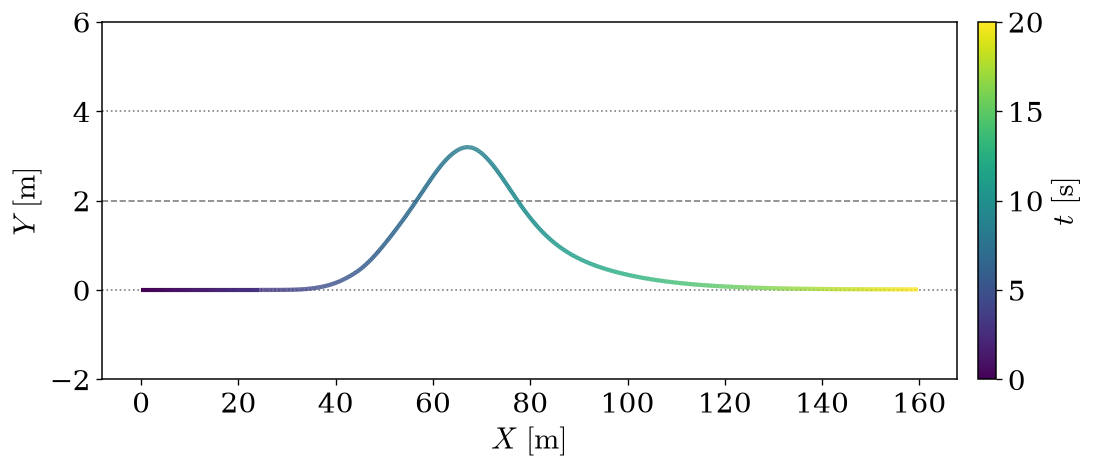

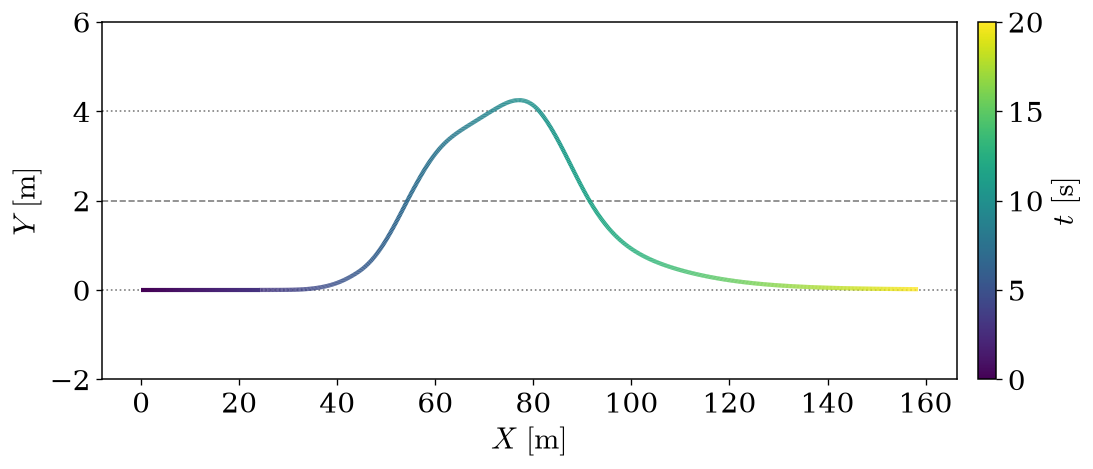

In [3]:
for run in runs:
    show(f"{run.name}_trajectory", plot_trajectory(run))


## Frame della manovra

Ego blu, human arancione e previsione MPC tratteggiata. Tempi e finestra spaziale si scelgono nella configurazione.

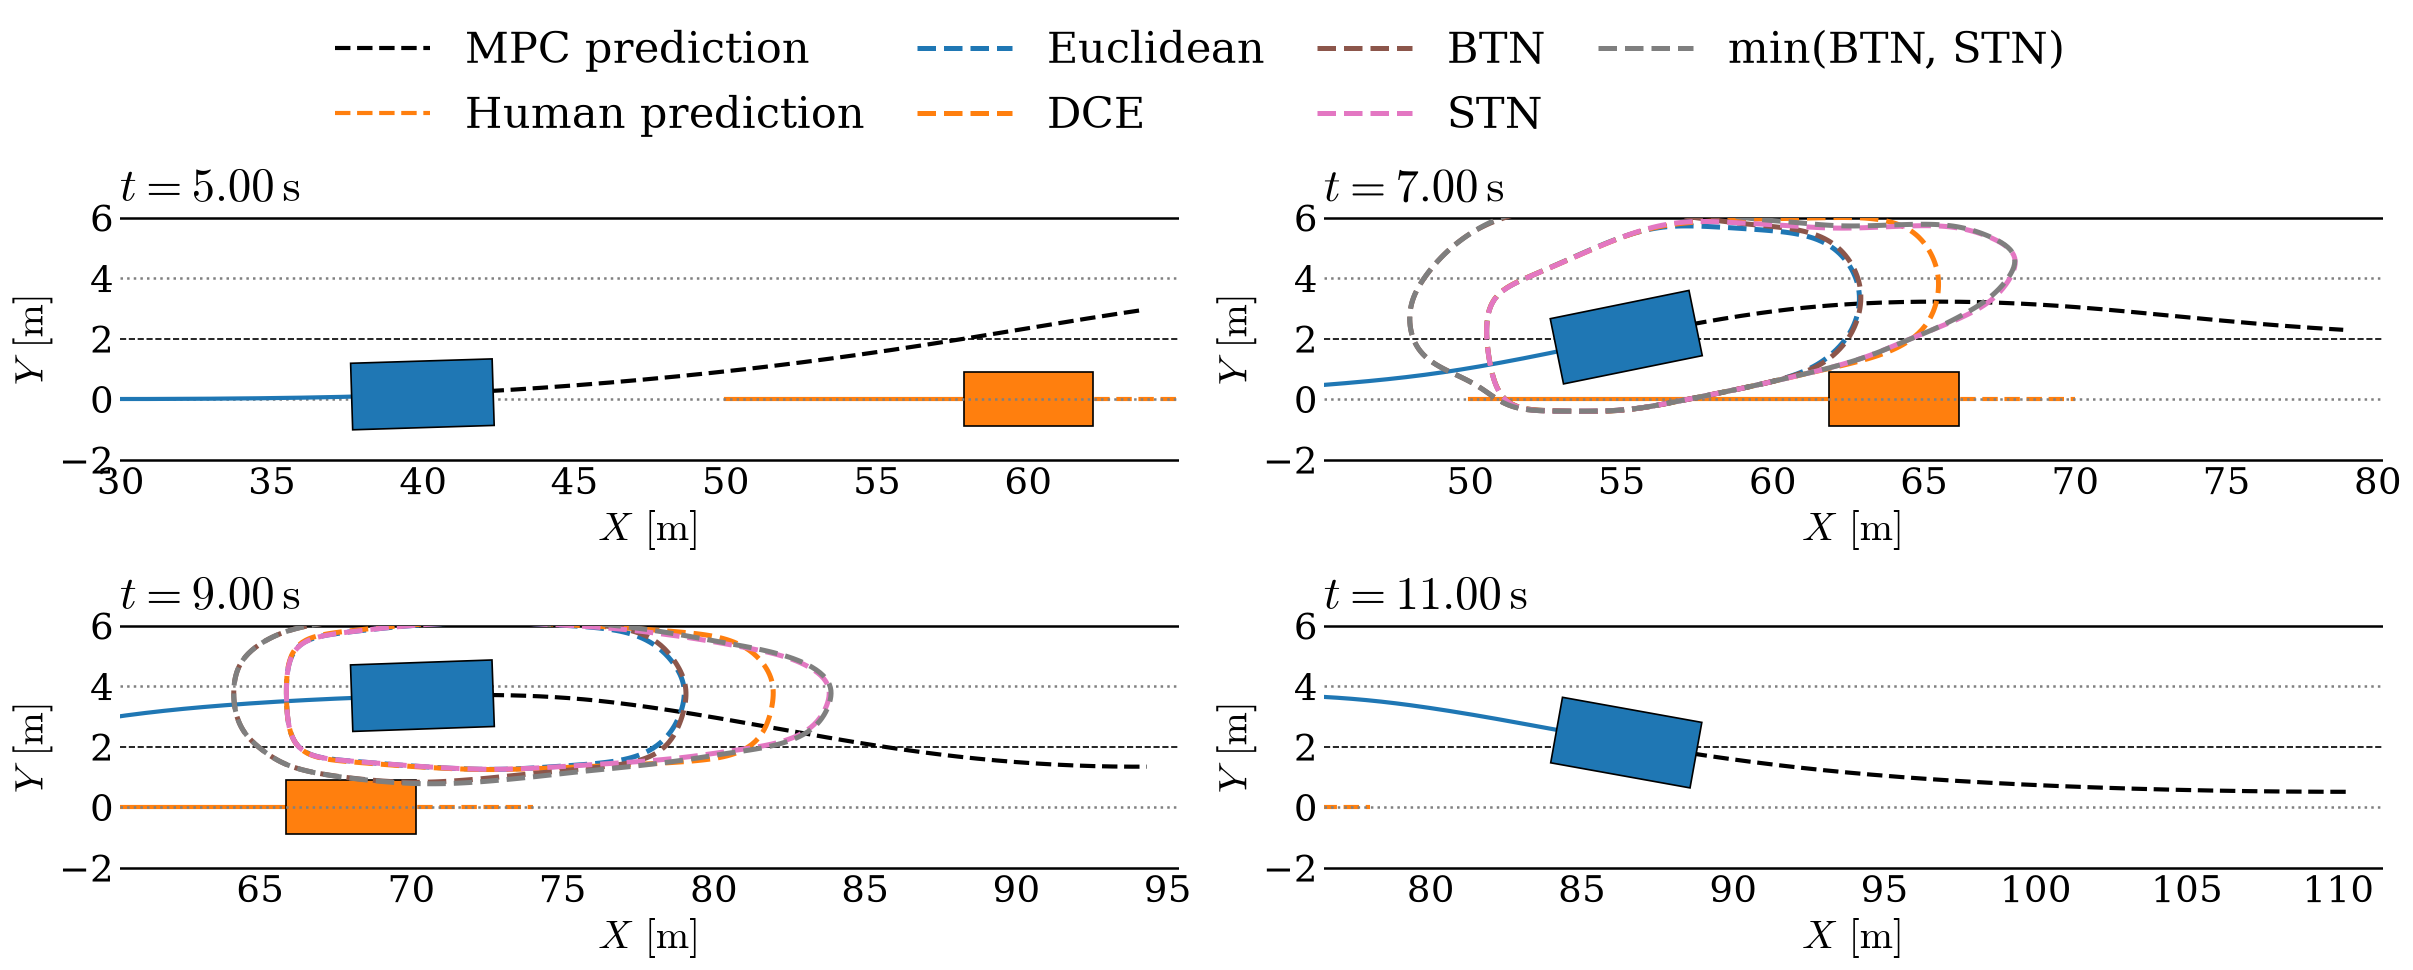

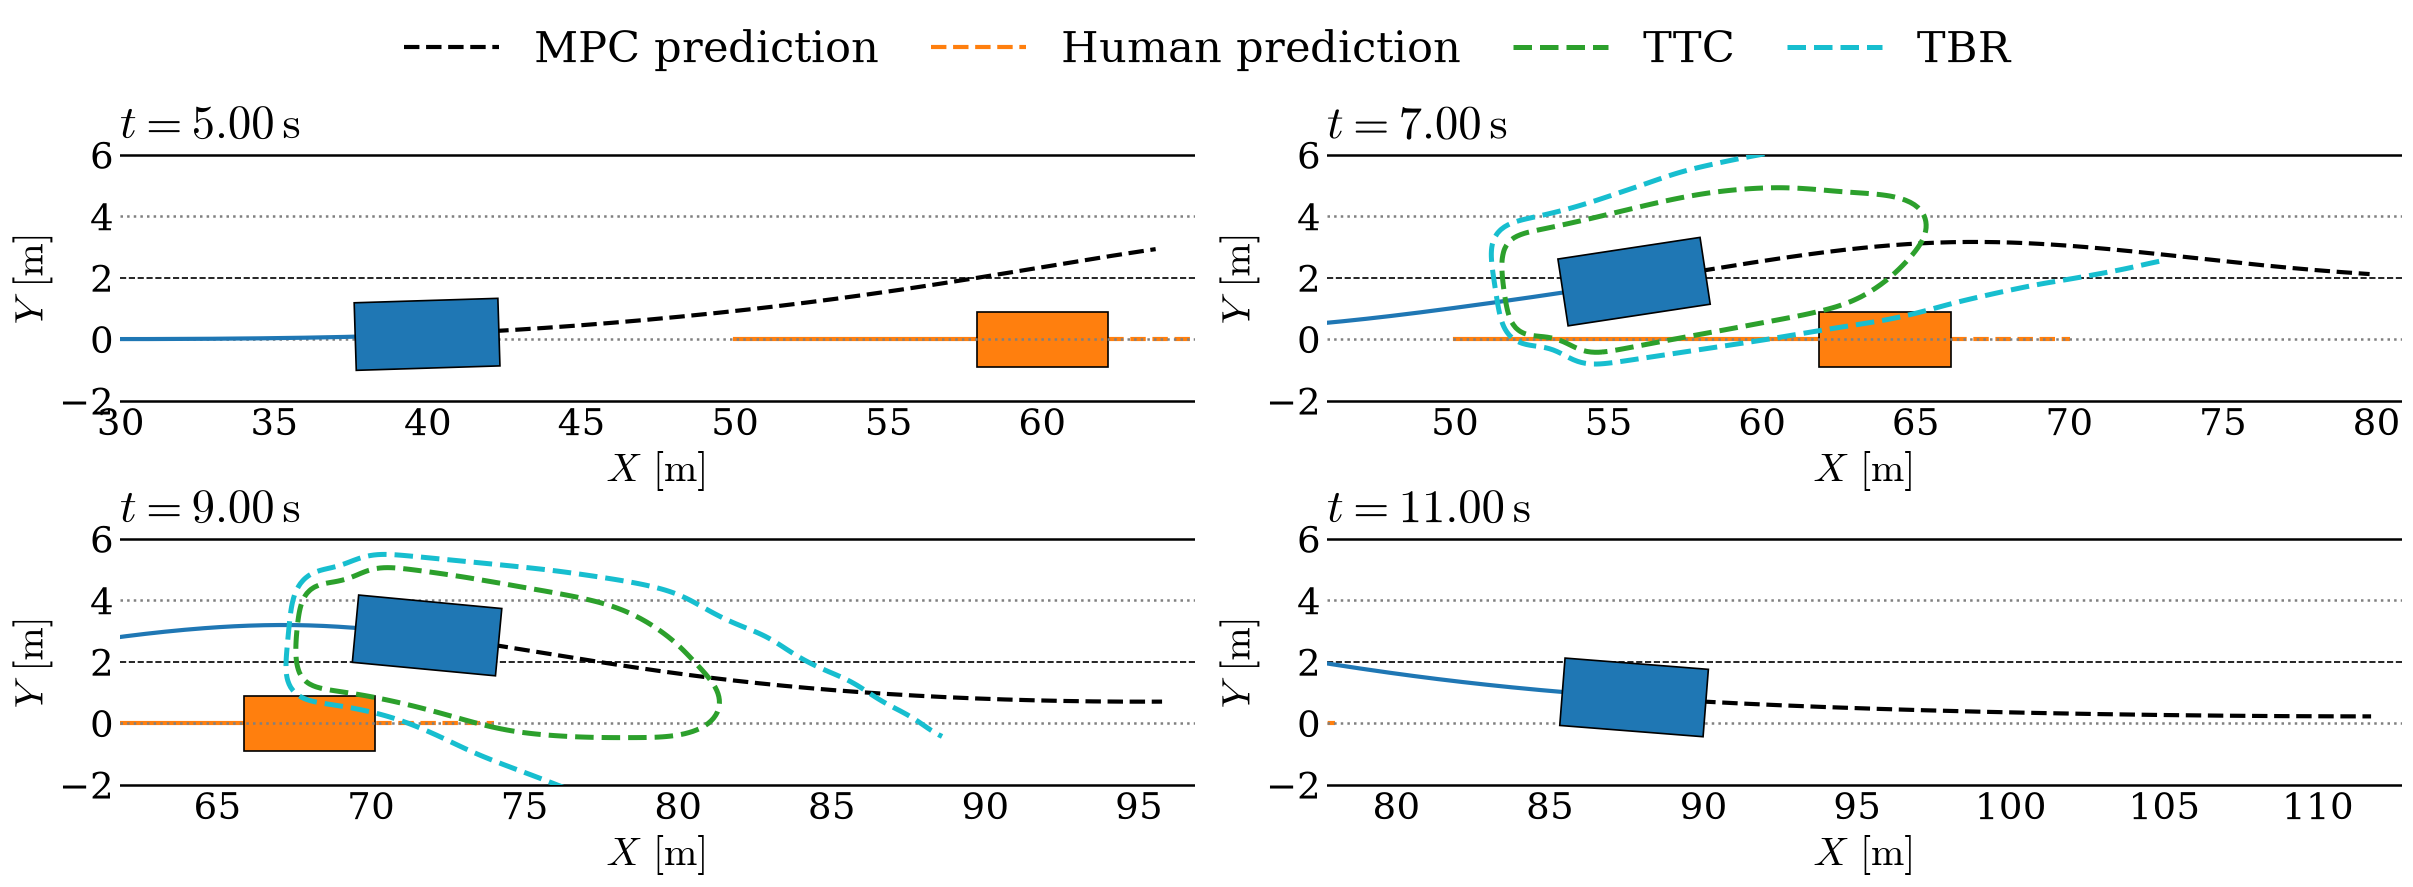

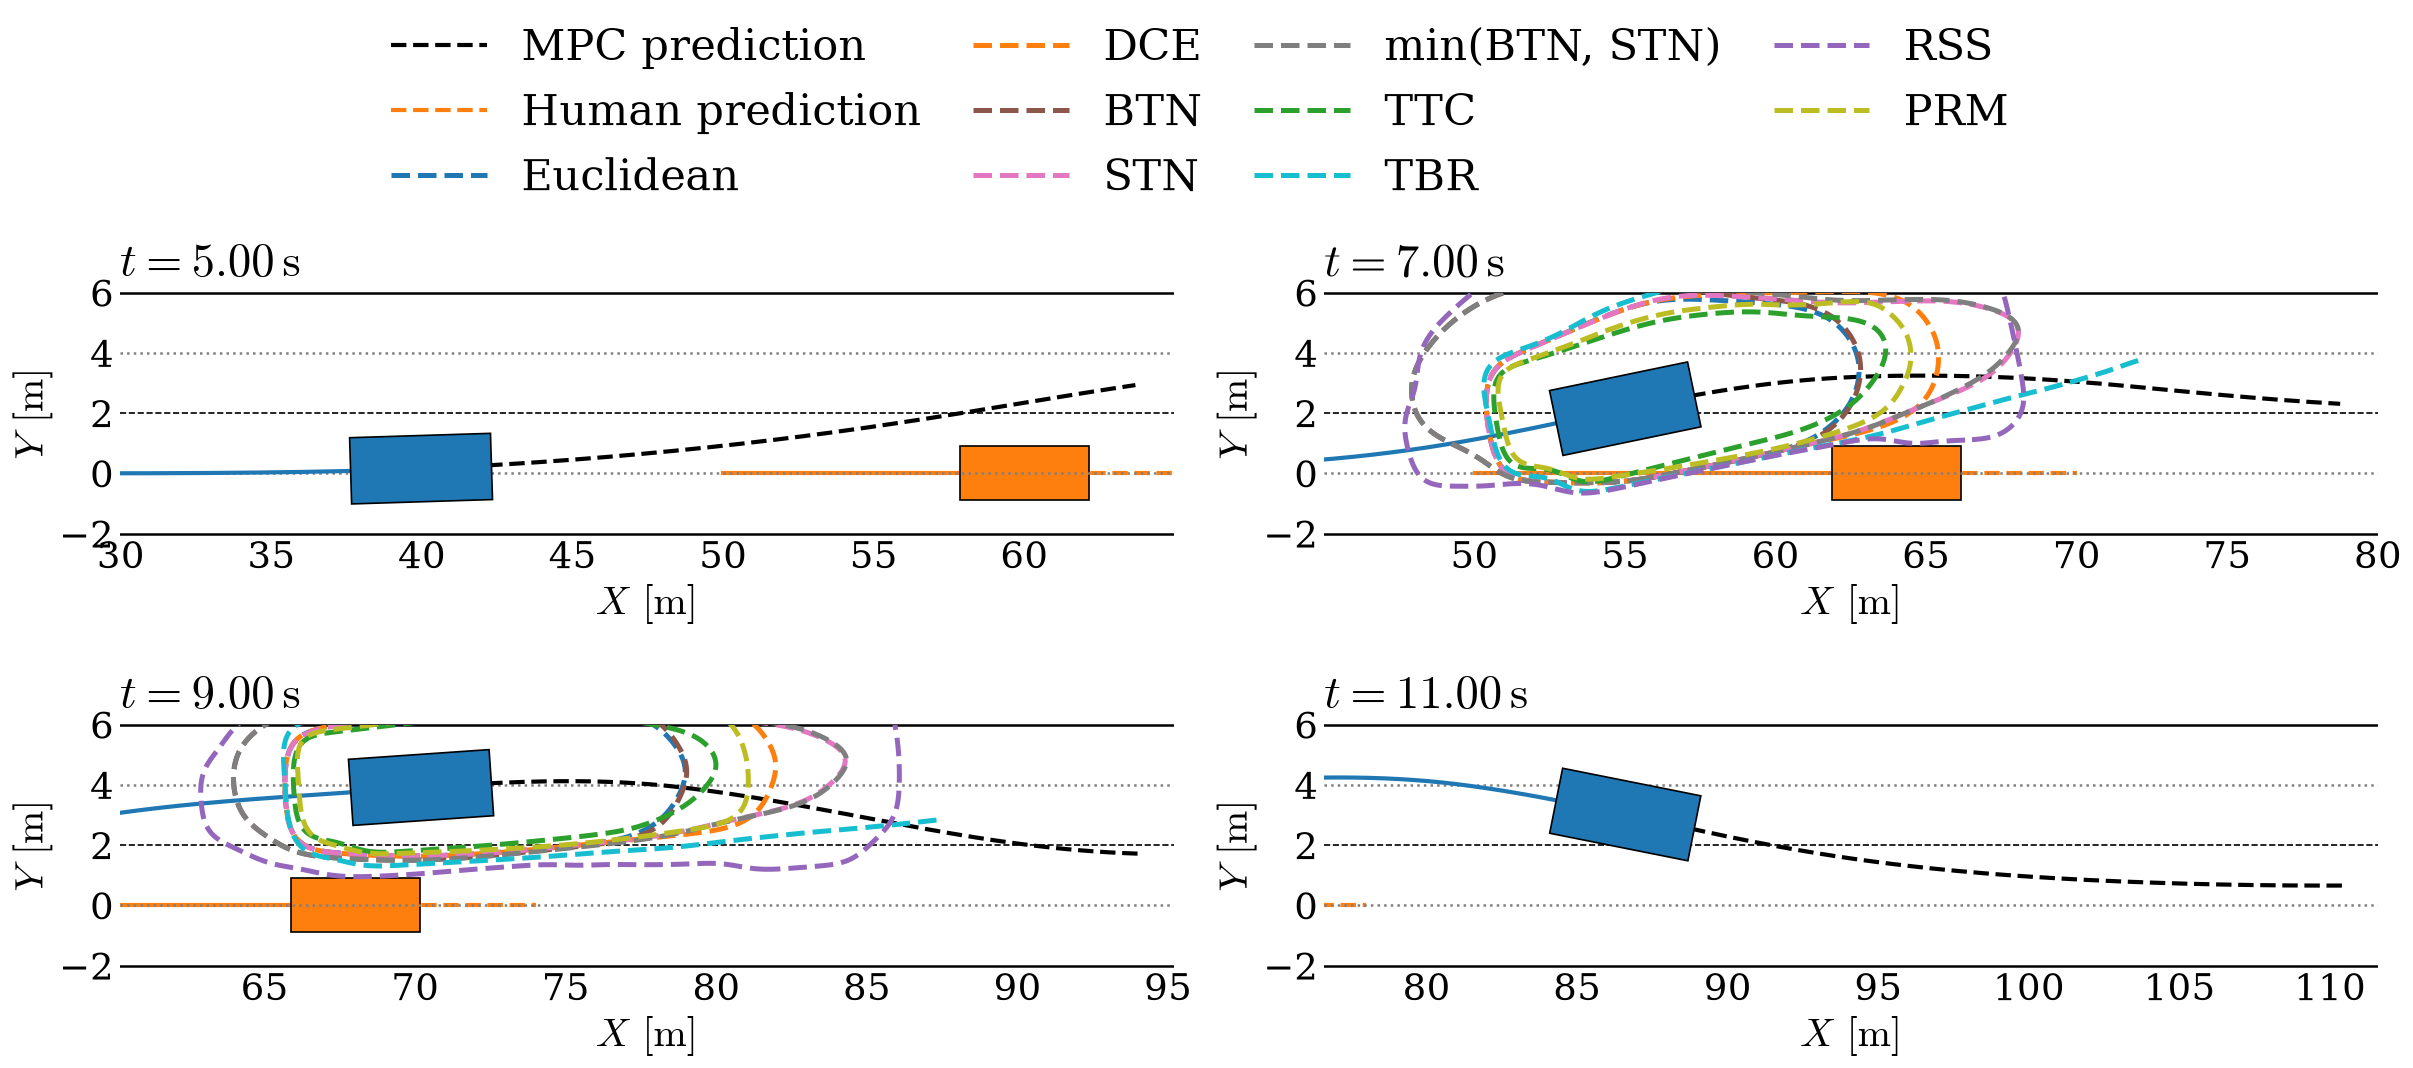

In [4]:
for run in runs:
    fig = plot_frames(
        run,
        FRAME_TIMES,
        behind=VIEW_BEHIND,
        ahead=VIEW_AHEAD,
        ncols=2,
    )

    if run.name == "multi_space":
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, 1.20))

    if run.name == "multi_all":
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, 1.25))

    show(f"{run.name}_frames", fig)

## Frame per summary

/tmp/ipykernel_1478949/2092253105.py:20: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


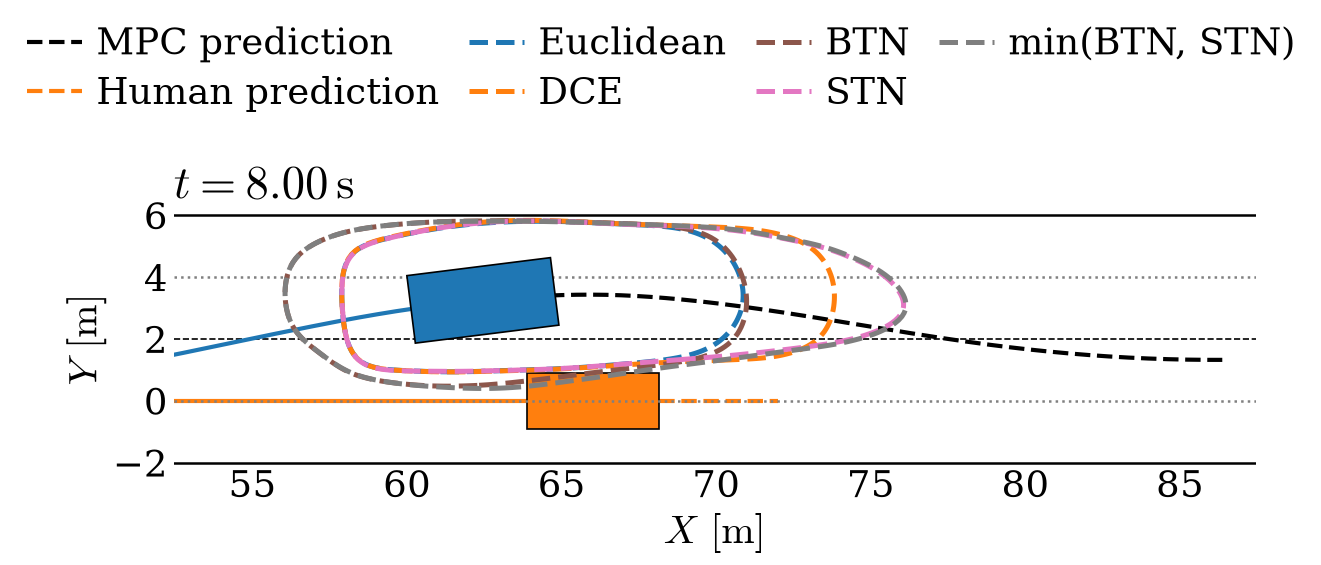

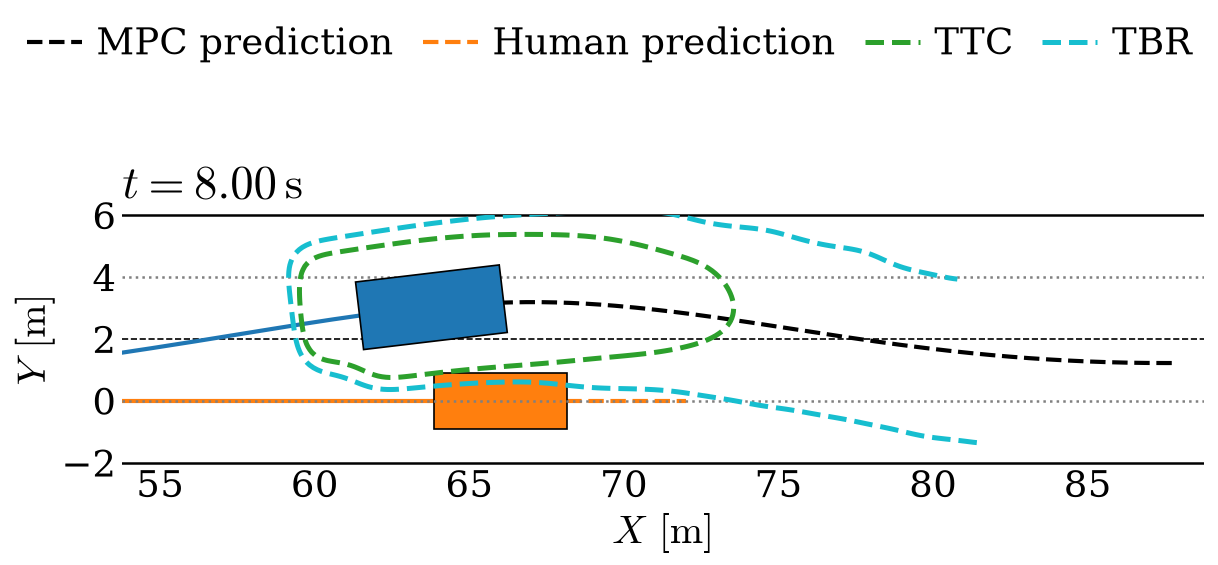

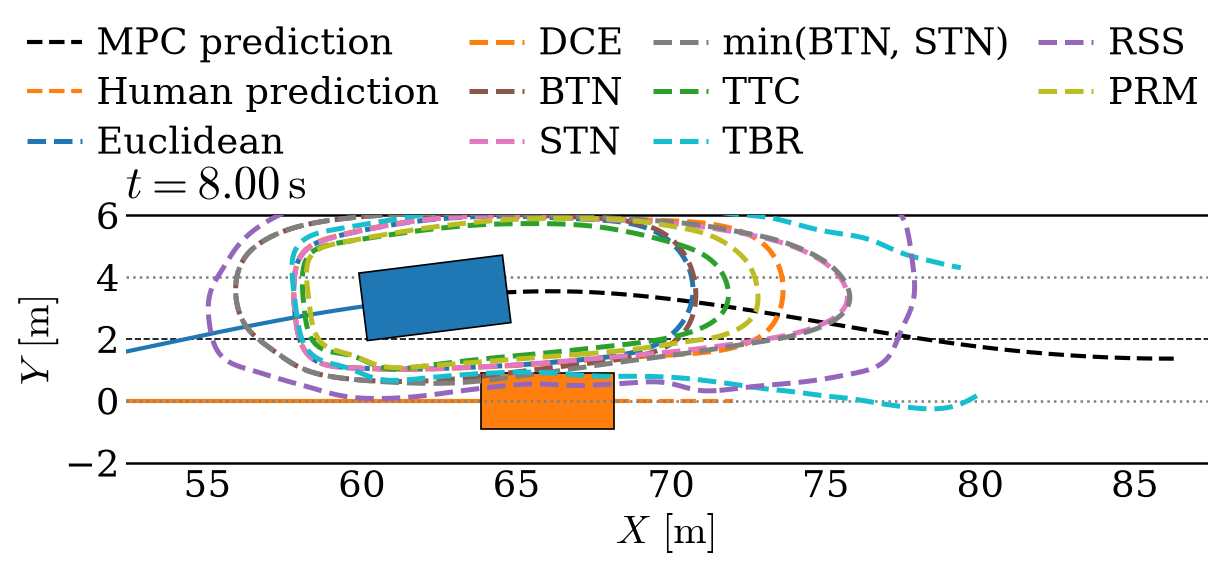

In [5]:
for run in runs:
    fig = plot_frames(
        run,
        (8.0,),
        behind=VIEW_BEHIND,
        ahead=VIEW_AHEAD,
        ncols=1,
    )

    if fig.legends:
        original_legend = fig.legends[0]
        handles = list(original_legend.legend_handles)
        labels = [text.get_text() for text in original_legend.get_texts()]

        for legend in list(fig.legends):
            legend.remove()

        fig.set_layout_engine(None)
        fig.set_size_inches(10, 4.8)
        fig.subplots_adjust(
            left=0.10,
            right=0.98,
            bottom=0.18,
            top=0.65,
        )

        fig.legend(
            handles,
            labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.1),
            ncol=4,
            fontsize=22,
            columnspacing=0.8,
            handlelength=1.5,
            handletextpad=0.4,
            labelspacing=0.35,
            frameon=False,
        )

    show(f"{run.name}_single_frame", fig)

## Stati ego

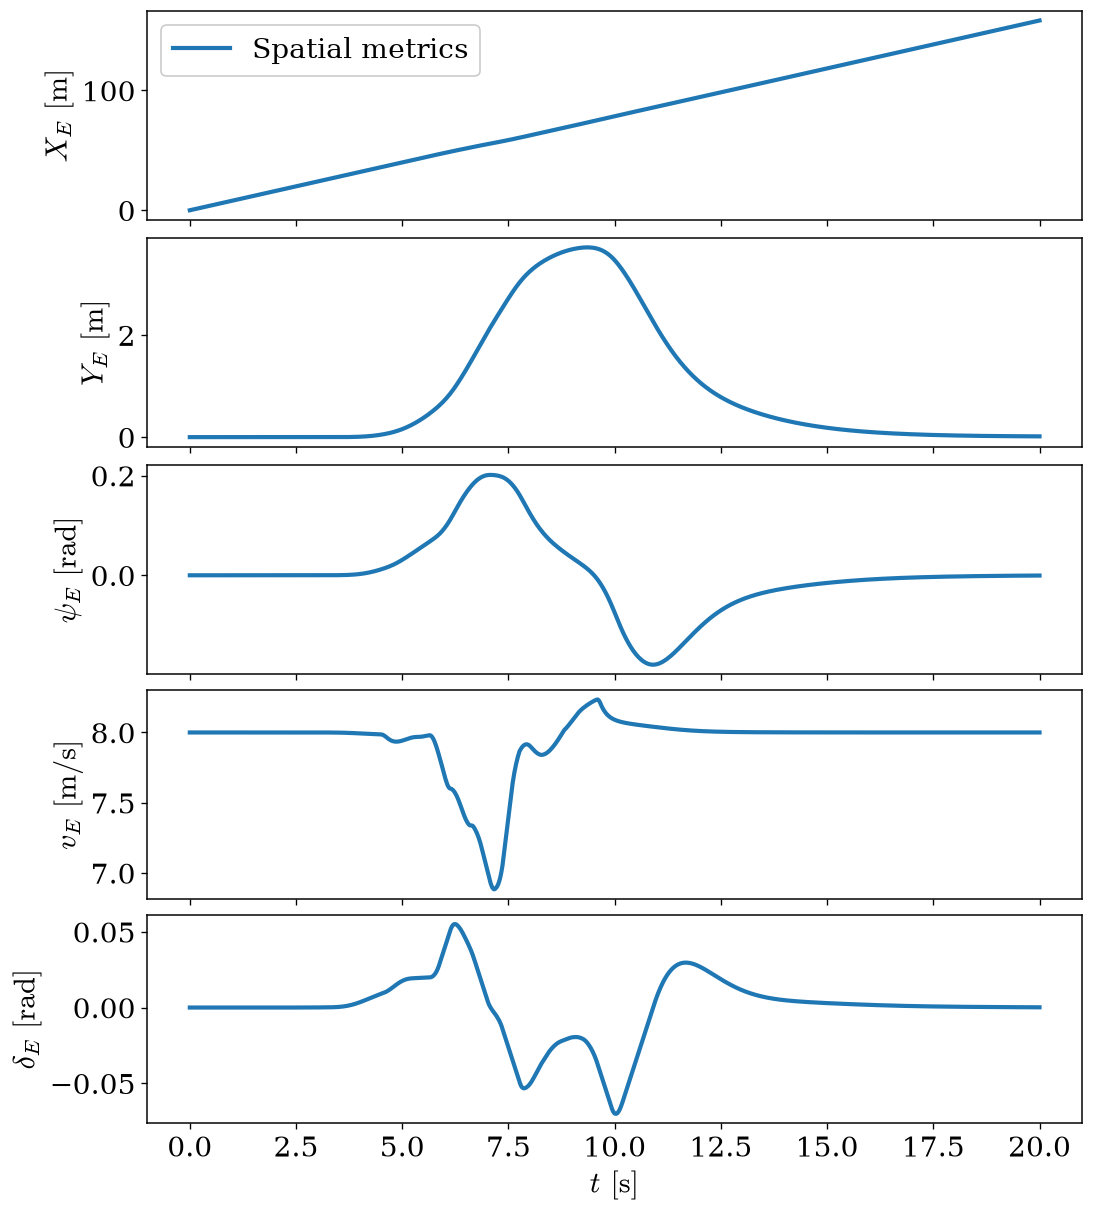

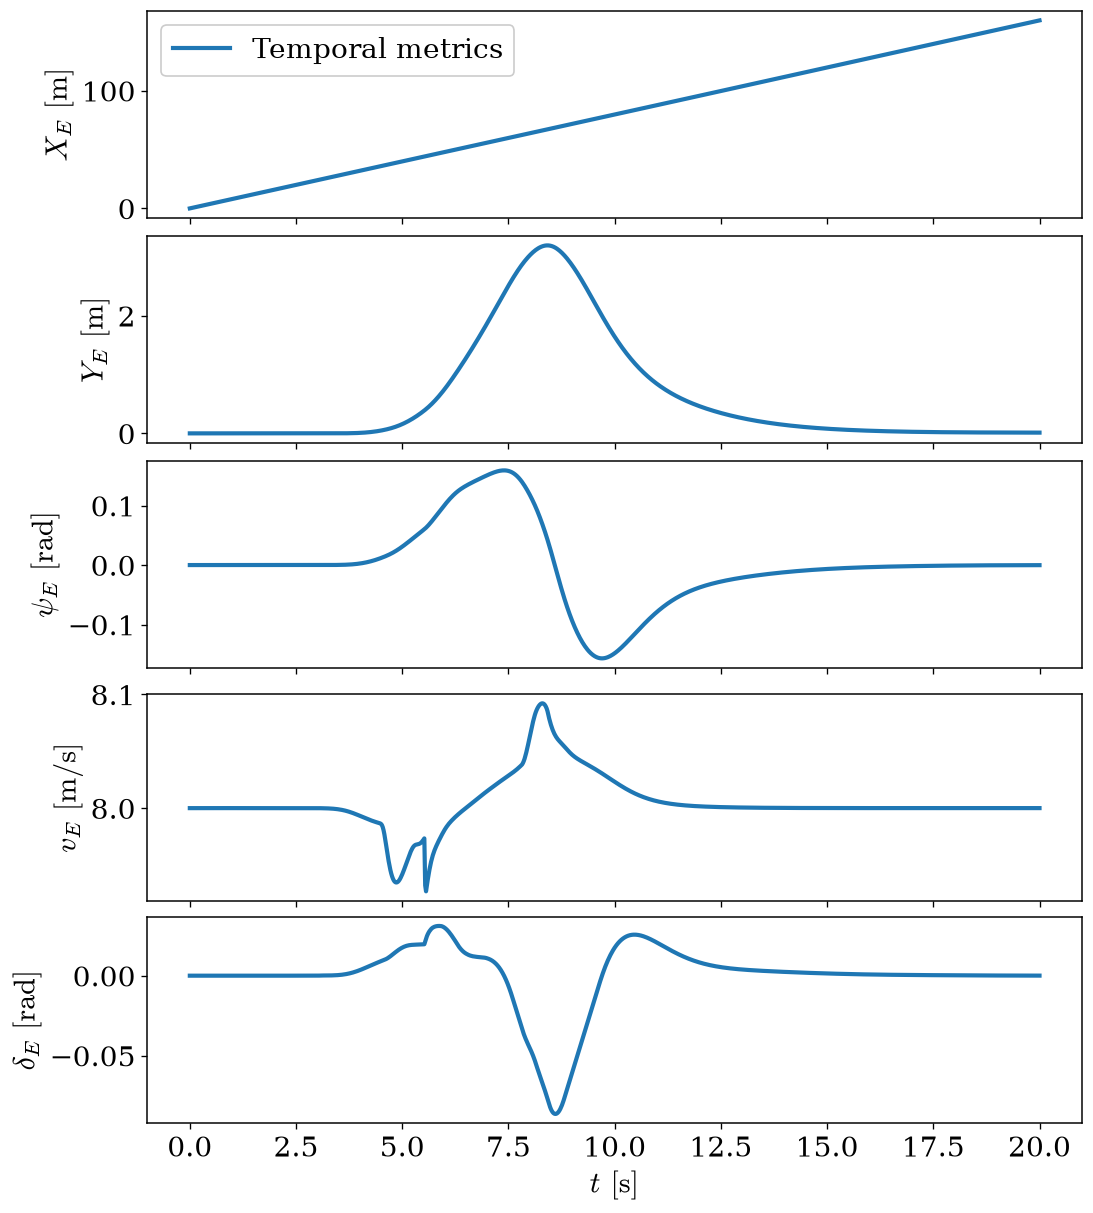

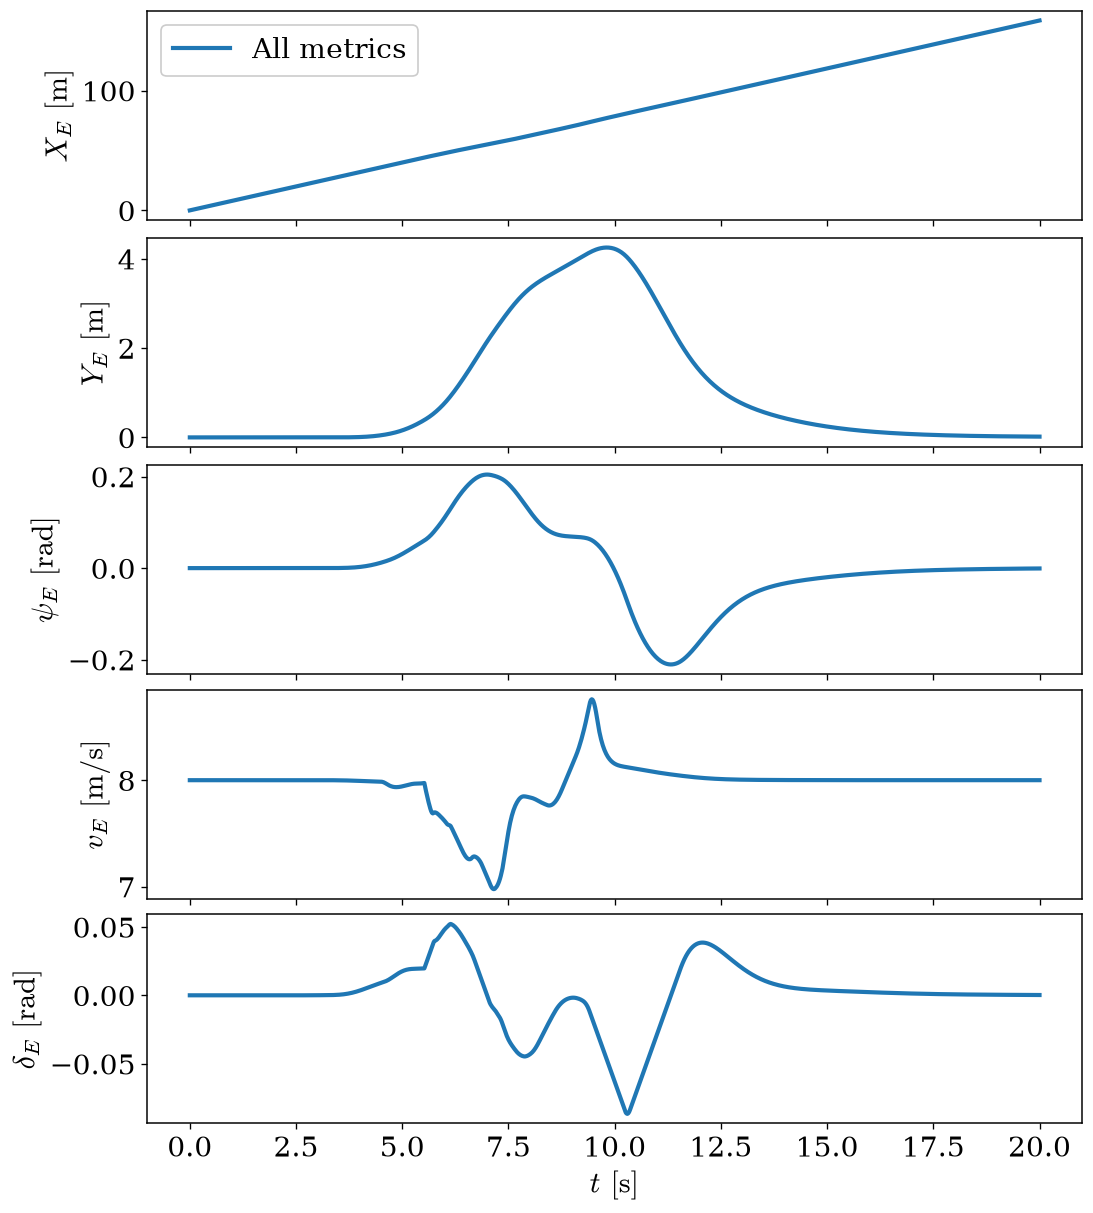

In [6]:
for run in runs:
    show(f"{run.name}_states", plot_states(run))


## Comandi ego

Ordine dei comandi salvati: steering rate, accelerazione.

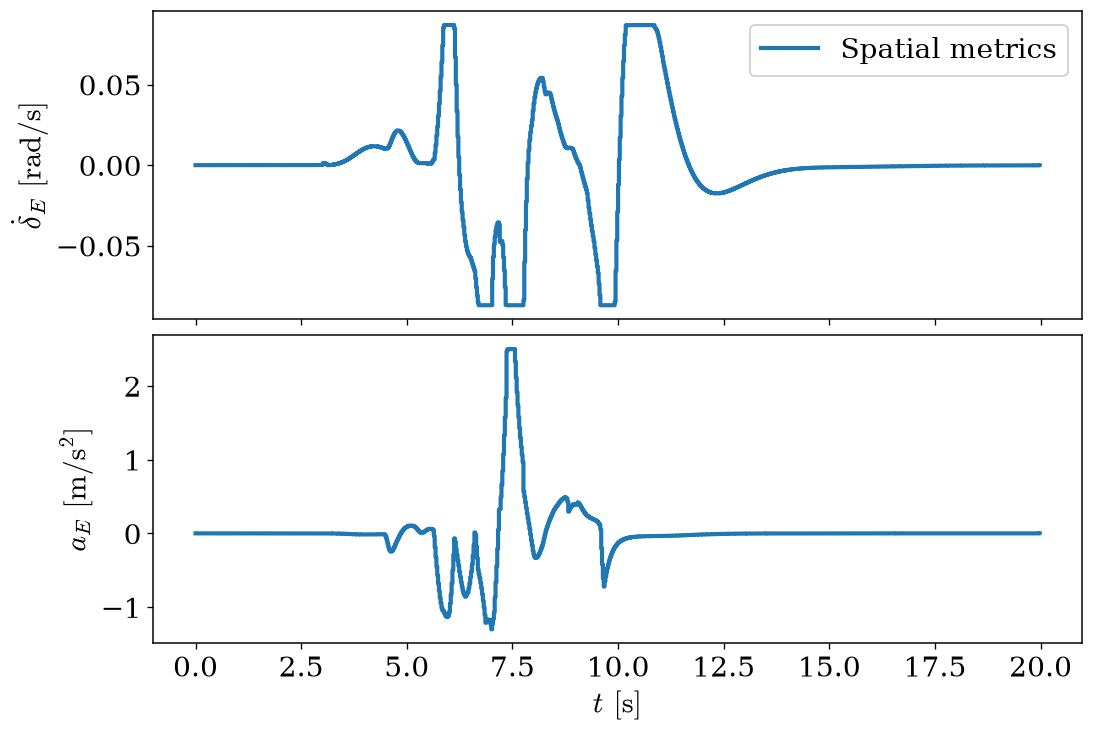

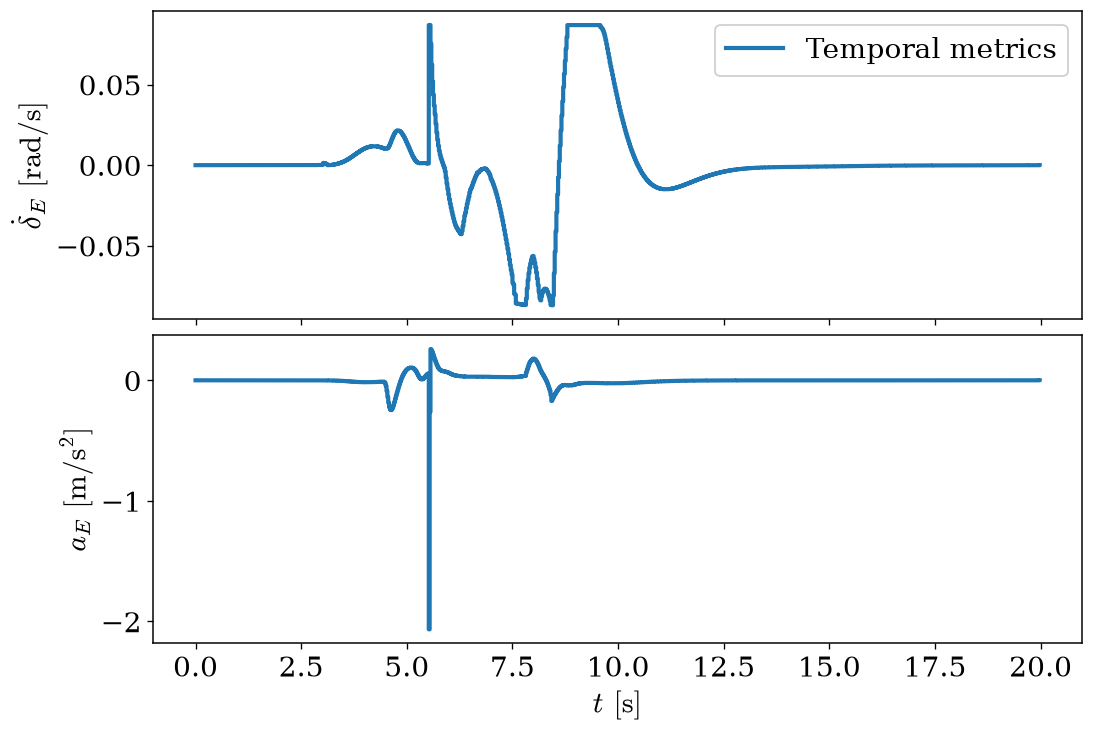

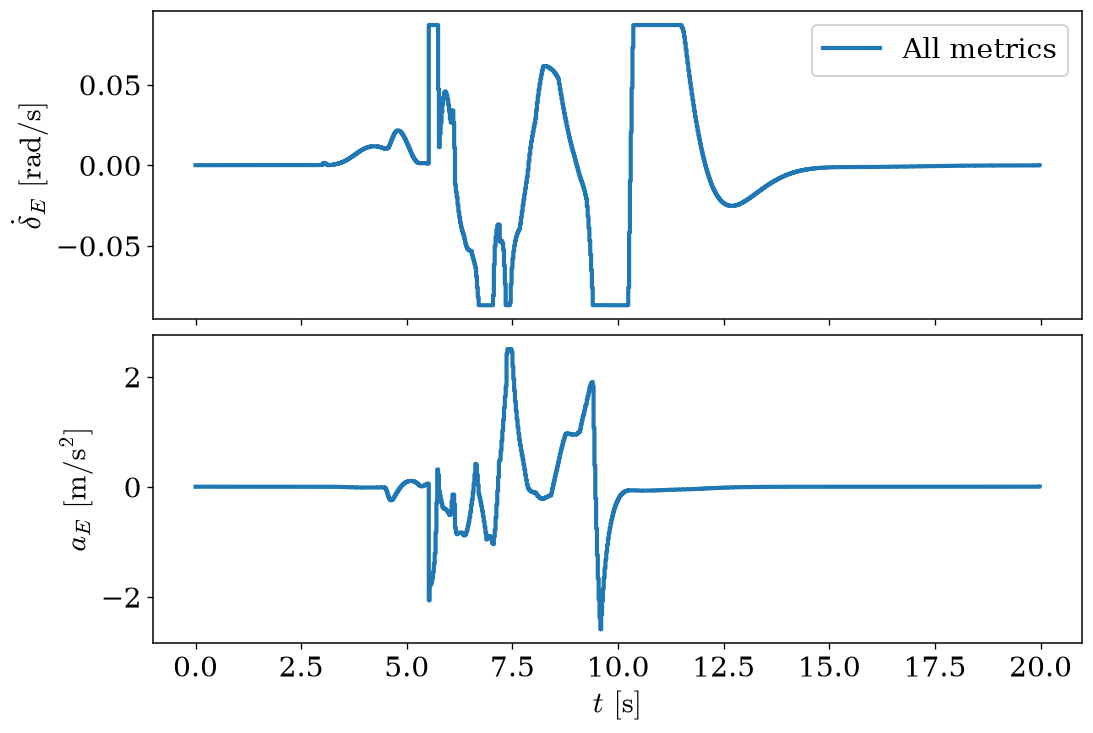

In [7]:
for run in runs:
    show(f"{run.name}_commands", plot_commands(run))


## Value function

Sono mostrati soltanto i campioni disponibili nel dominio BRT. Non vengono normalizzate le scale delle metriche.

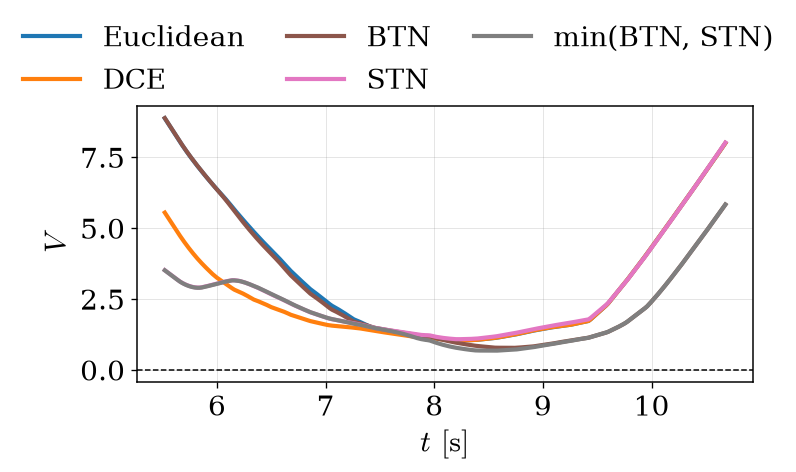

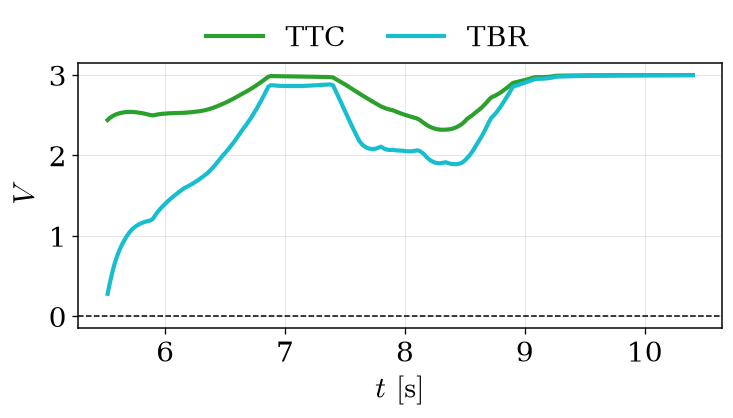

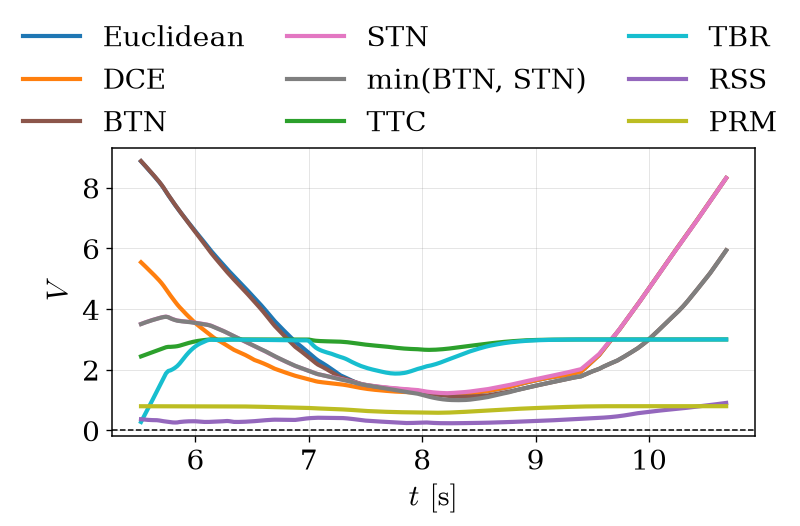

In [8]:
for run in runs:
    fig = plot_values(run)
    ax = fig.axes[0]

    handles, labels = ax.get_legend_handles_labels()

    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ncols = min(3, len(labels))
    nrows = (len(labels) + ncols - 1) // ncols

    width, height = fig.get_size_inches()
    fig.set_size_inches(width, height + 0.45 * nrows)

    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=ncols,
        frameon=False,
        columnspacing=1.5,
        handlelength=2,
    )

    show(f"{run.name}_values", fig)

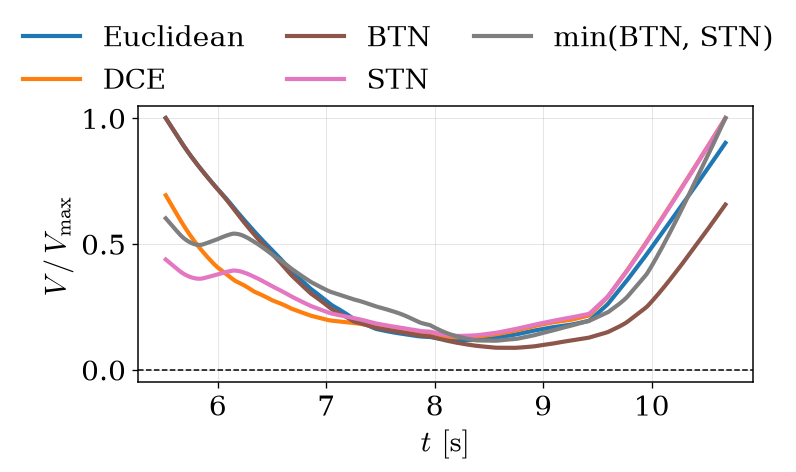

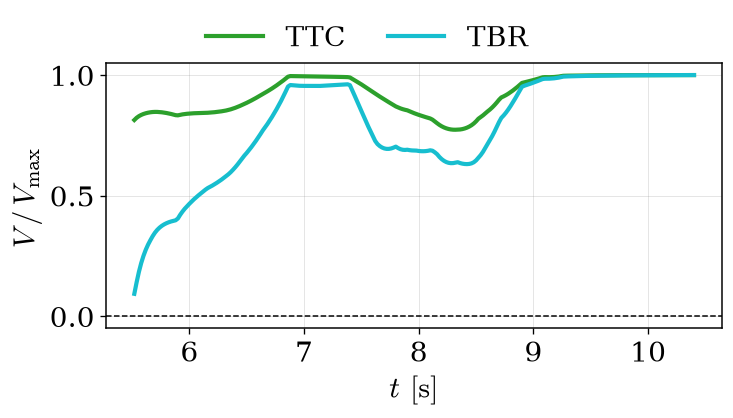

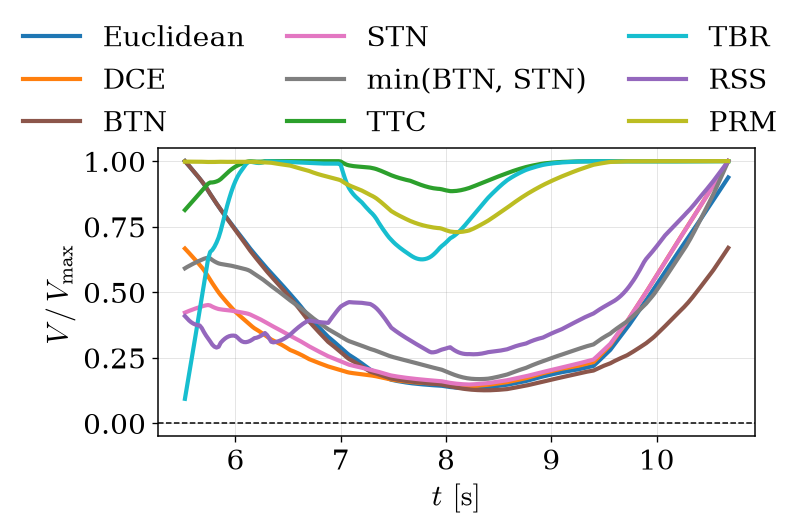

In [9]:
for run in runs:
    fig = plot_values(run)
    ax = fig.axes[0]

    handles, labels = ax.get_legend_handles_labels()

    for line in handles:
        values = np.asarray(line.get_ydata(), dtype=float)
        finite_values = values[np.isfinite(values)]

        if not len(finite_values):
            continue

        maximum = finite_values.max()

        if maximum == 0:
            raise ValueError(
                f"{run.name}, {line.get_label()}: massimo nullo, "
                "normalizzazione non definita."
            )

        line.set_ydata(values / maximum)

    ax.relim()
    ax.autoscale_view(scalex=False, scaley=True)
    ax.set_ylabel(r"$V\,/\,V_{\max}$")

    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ncols = min(3, len(labels))
    nrows = (len(labels) + ncols - 1) // ncols

    width, height = fig.get_size_inches()
    fig.set_size_inches(width, height + 0.45 * nrows)

    fig.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=ncols,
        frameon=False,
        columnspacing=1.5,
        handlelength=2,
    )

    show(f"{run.name}_values_normalized", fig)

## Limiti HJ sui comandi

Gli intervalli sono condizionati al valore registrato dell’altro comando, allo stage HJ_STAGE. Non sono proiezioni indipendenti del piano comandi. Il verde indica l’intervallo comune; il rosso tratteggiato i limiti fisici. Con HJ_SOFTENED=False si esclude lo slack.

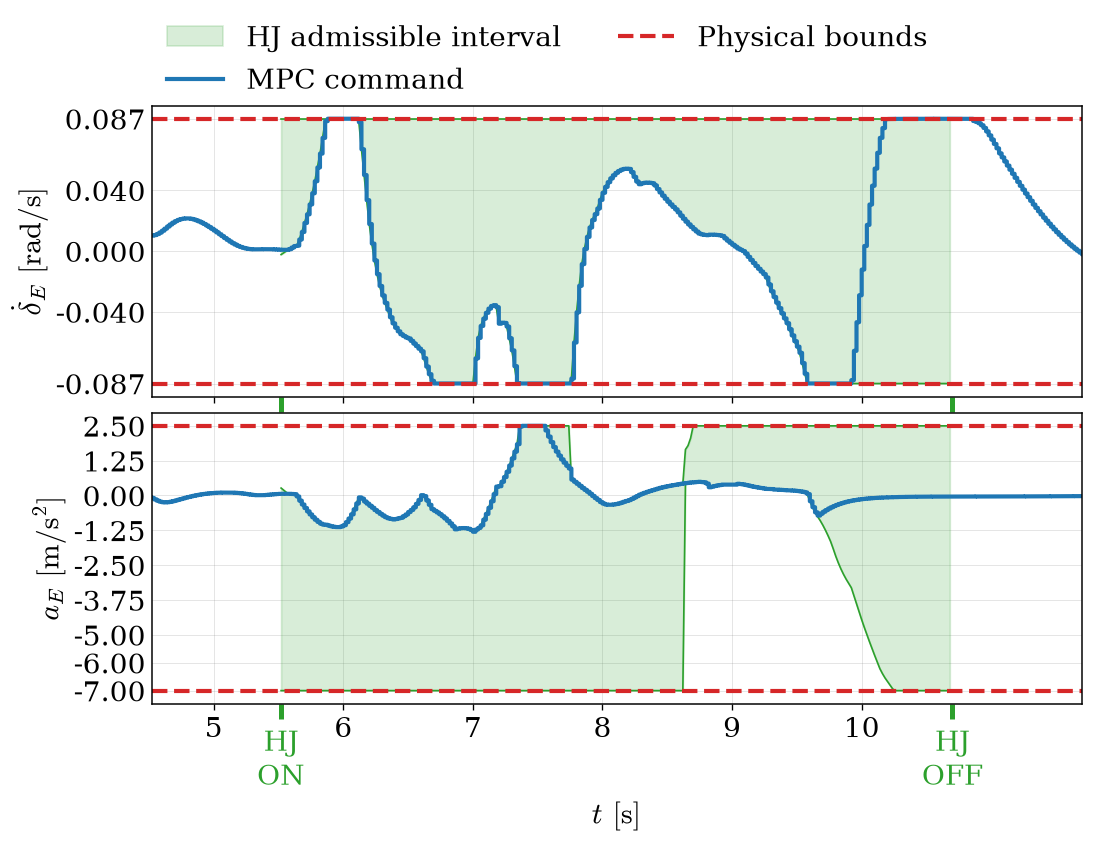

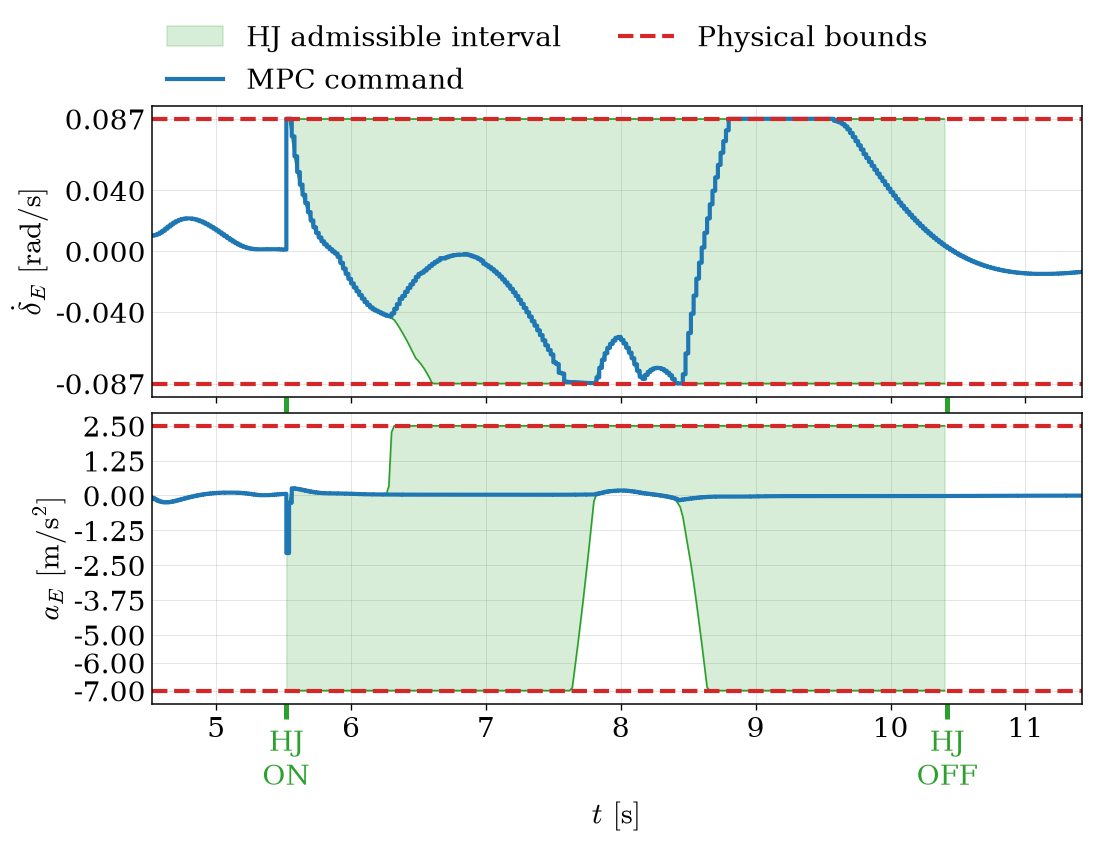

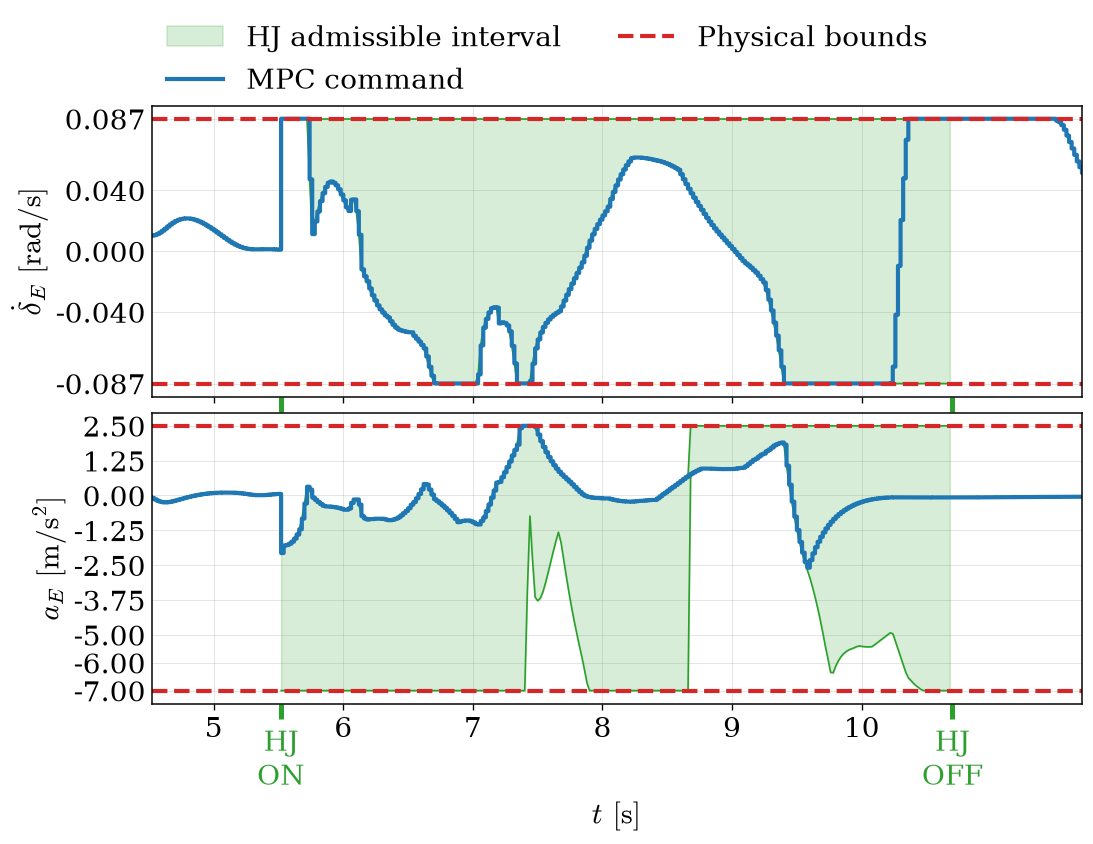

In [10]:
for run in runs:
    show(f"{run.name}_hj_limits", plot_hj_limits(
        run, stage=HJ_STAGE, softened=HJ_SOFTENED
    ))


## Piano dei comandi

Intersezione congiunta dei vincoli HJ e dei limiti fisici. La regione non comprende i vincoli di strada o la fattibilità dinamica futura.

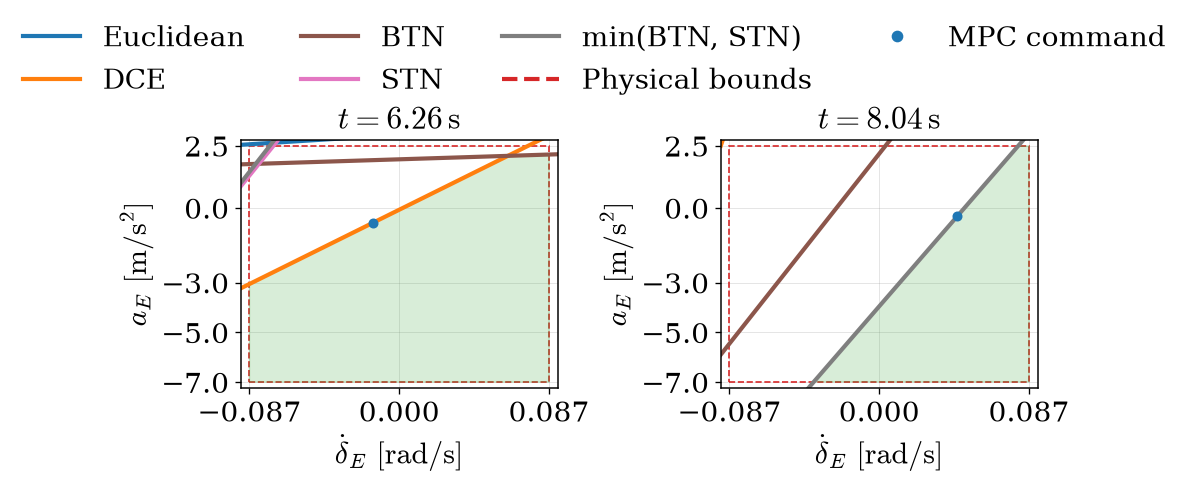

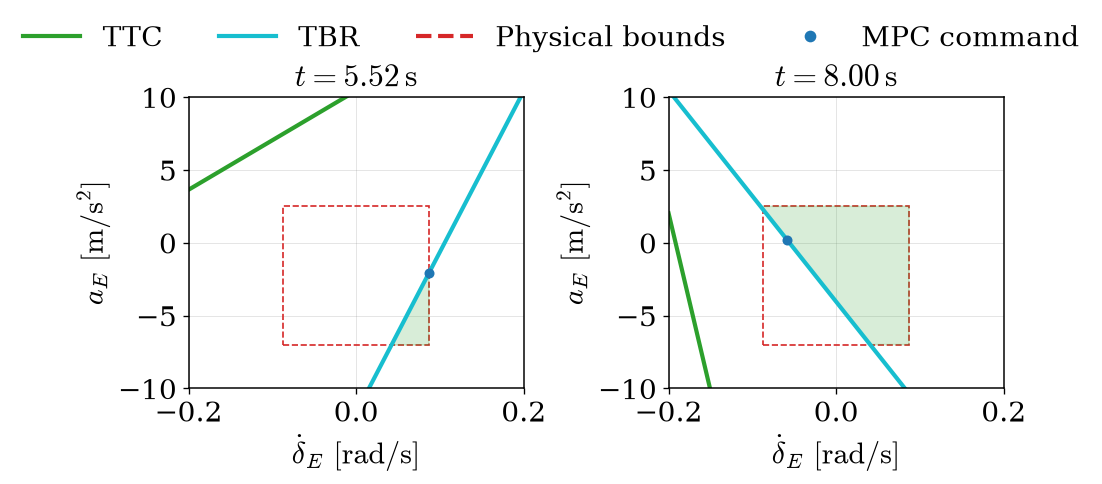

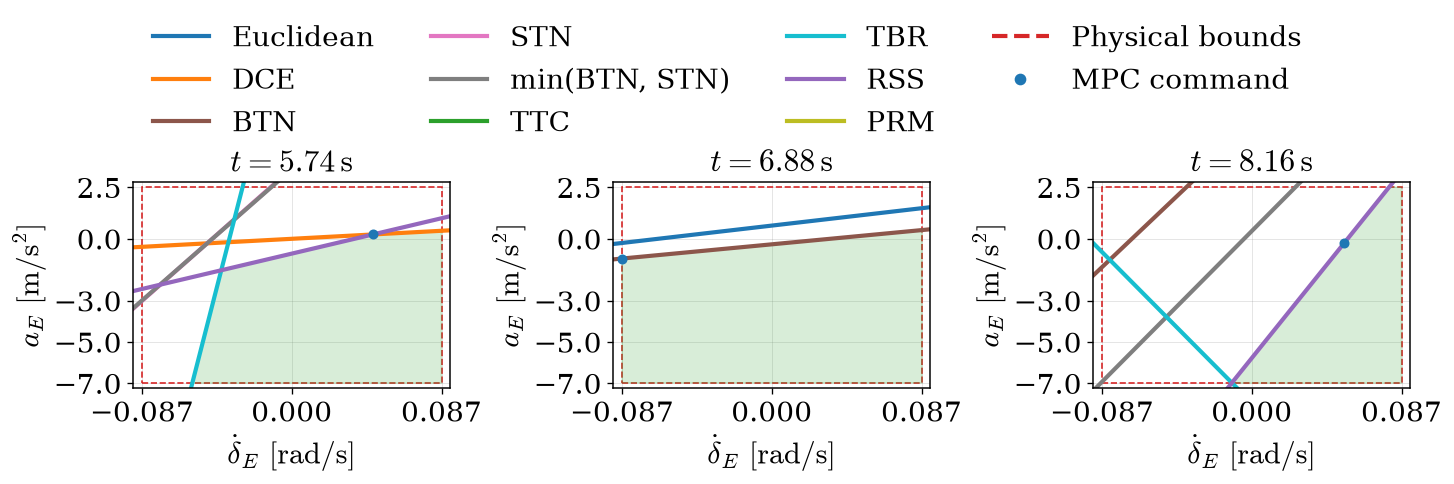

In [11]:
plane_times_by_run = {
    "multi_space": (6.26, 8.04),
    "multi_time": (5.52, 8.00),
    "multi_all": (5.74, 6.88, 8.16),
    #"multi_all": (5.74,),
}

for run in runs:
    show(
        f"{run.name}_command_planes",
        plot_command_planes(
            run,
            times=plane_times_by_run[run.name],
            stage=HJ_STAGE,
            softened=HJ_SOFTENED,
            zoom_to_constraints=(run.name == "multi_time"),
            xlim=(-0.2, 0.2) if run.name == "multi_time" else None,
            ylim=(-10.0, 10.0) if run.name == "multi_time" else None,
        ),
    )

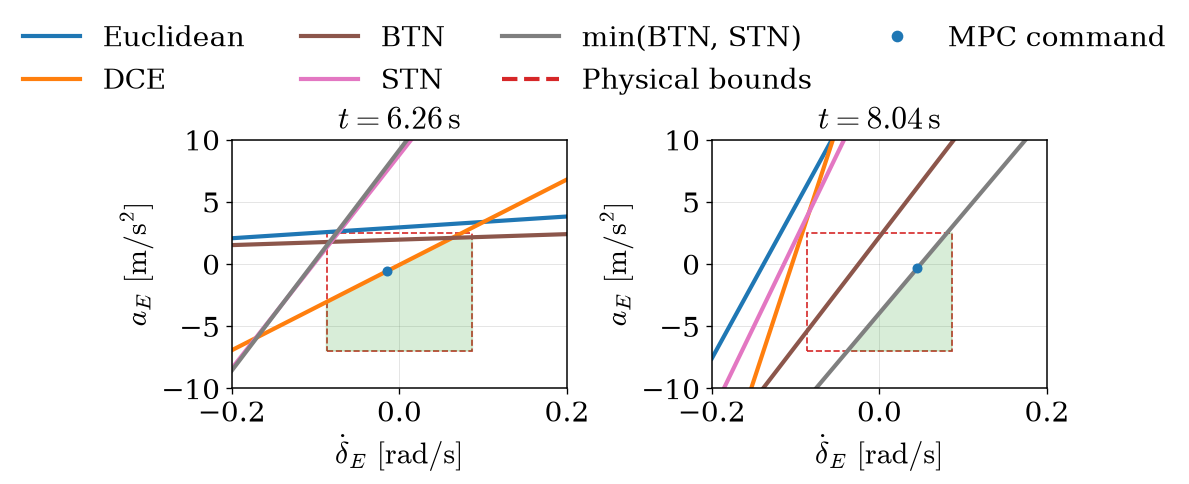

In [12]:
run_space = next(run for run in runs if run.name == "multi_space")

fig = plot_command_planes(
    run_space,
    times=(6.26, 8.04),
    stage=HJ_STAGE,
    softened=HJ_SOFTENED,
    zoom_to_constraints=True,
    xlim=(-0.2, 0.2),
    ylim=(-10.0, 10.0),
)

show("multi_space_command_planes_zoom_out", fig)

## Legenda compressa per summary

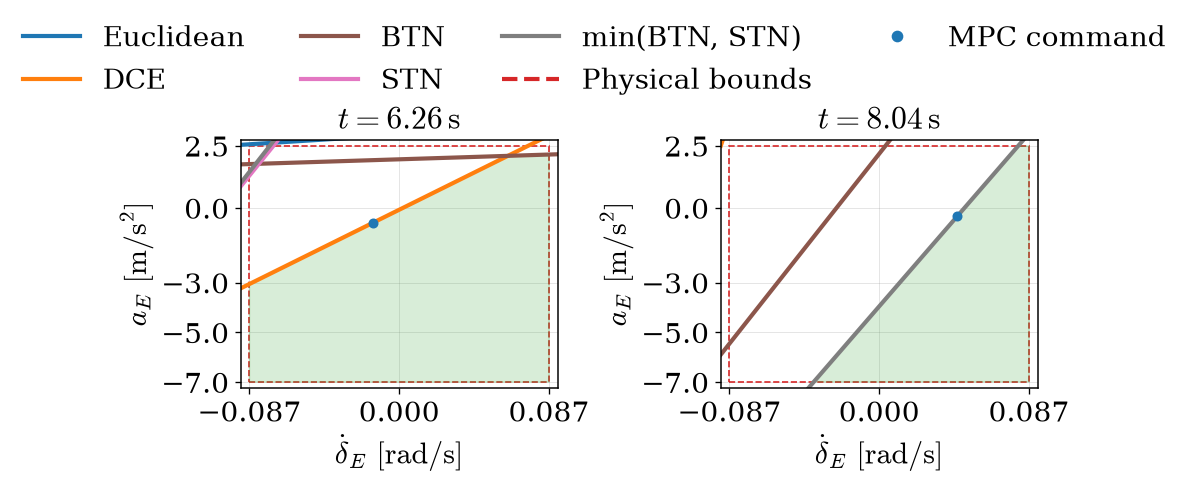

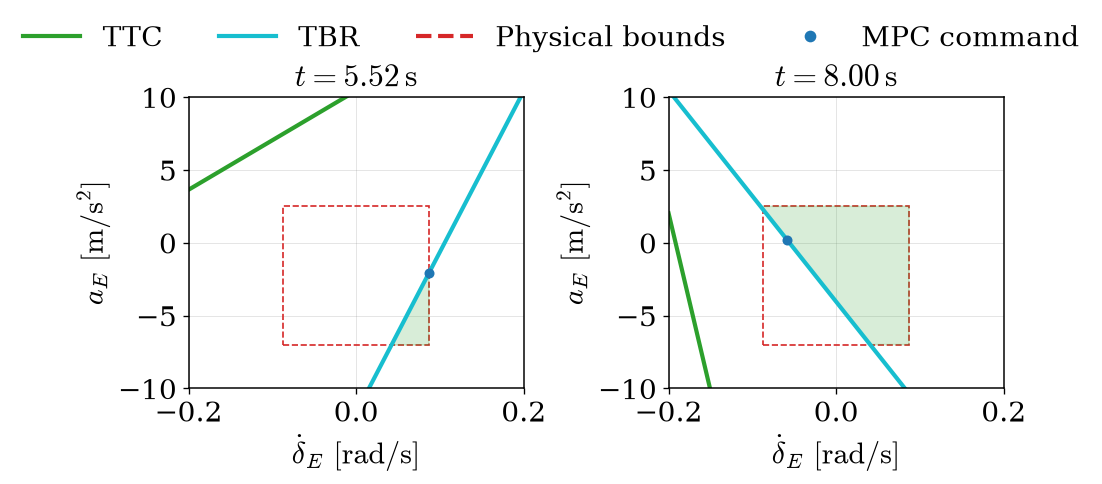

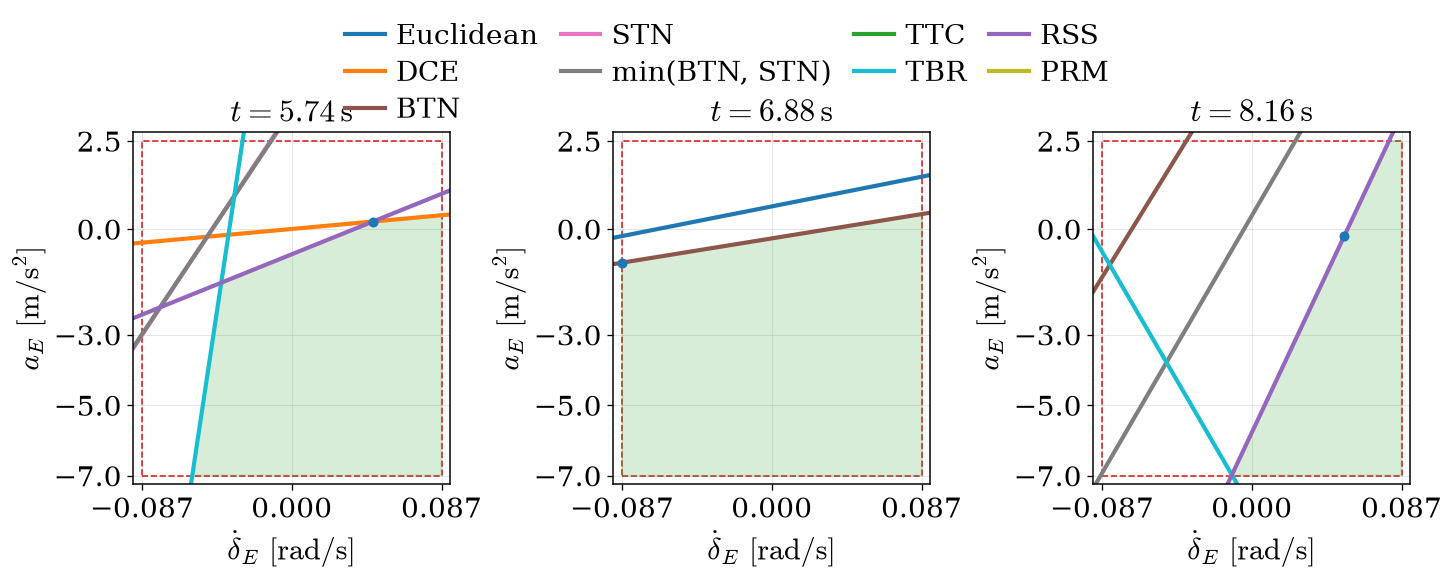

In [13]:
for run in runs:
    fig = plot_command_planes(
        run,
        times=plane_times_by_run[run.name],
        stage=HJ_STAGE,
        softened=HJ_SOFTENED,
        zoom_to_constraints=(run.name == "multi_time"),
        xlim=(-0.2, 0.2) if run.name == "multi_time" else None,
        ylim=(-10.0, 10.0) if run.name == "multi_time" else None,
    )

    if run.name == "multi_all":
        for legend in fig.legends:
            legend.remove()

        handles, labels = fig.axes[0].get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.2),
            ncol=4,
            columnspacing=0.8,
            handlelength=1.4,
            handletextpad=0.4,
            labelspacing=0.3,
            frameon=False,
        )

    show(f"{run.name}_command_planes_compressed", fig)

## Figure per singola metrica (facoltative)

In [14]:
if PER_METRIC_FIGURES:
    for run in runs:
        for metric in run.metrics:
            show(f"{run.name}_{metric}_value", plot_values(run, [metric]))
            show(f"{run.name}_{metric}_limits", plot_hj_limits(
                run, metric=metric, stage=HJ_STAGE, softened=HJ_SOFTENED
            ))


## Costi dell’OCP

Costo dell’orizzonte ottimizzato a ciascun passo, non costo istantaneo del solo comando applicato.

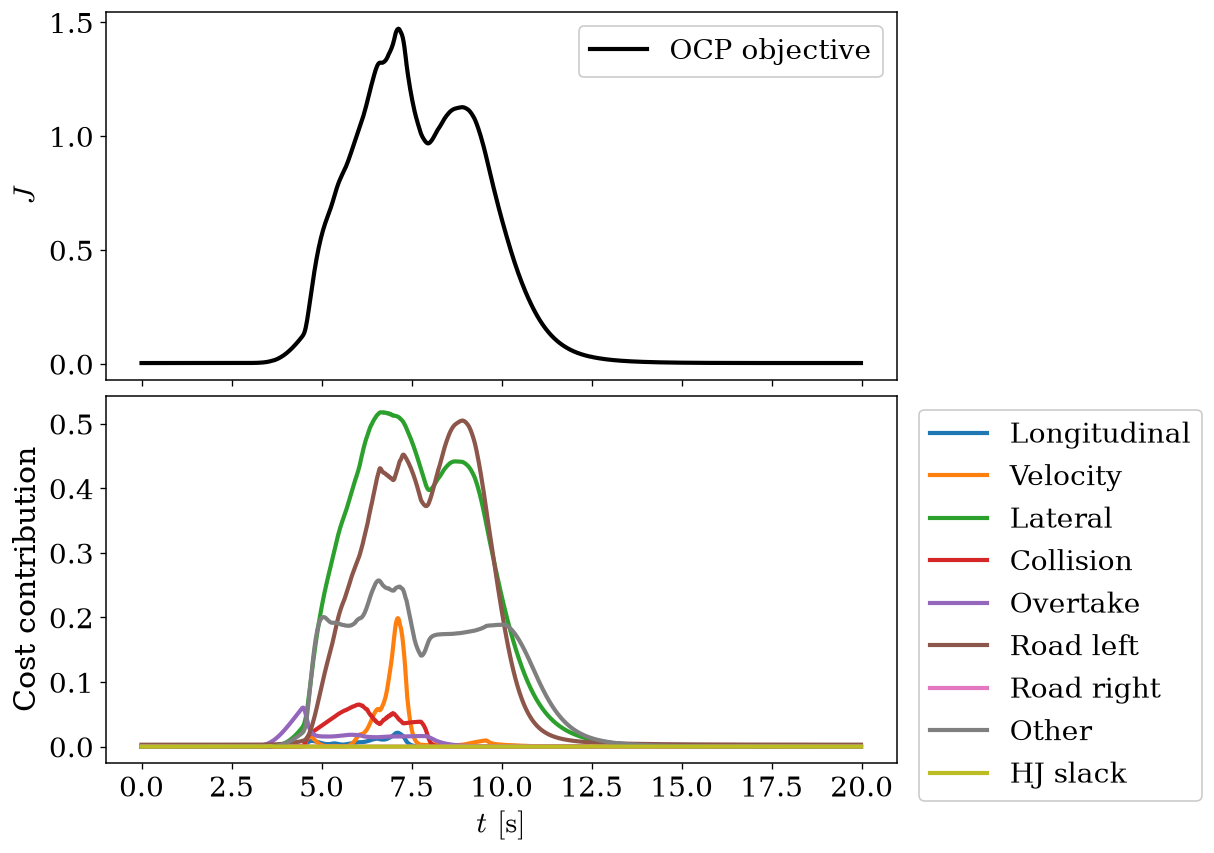

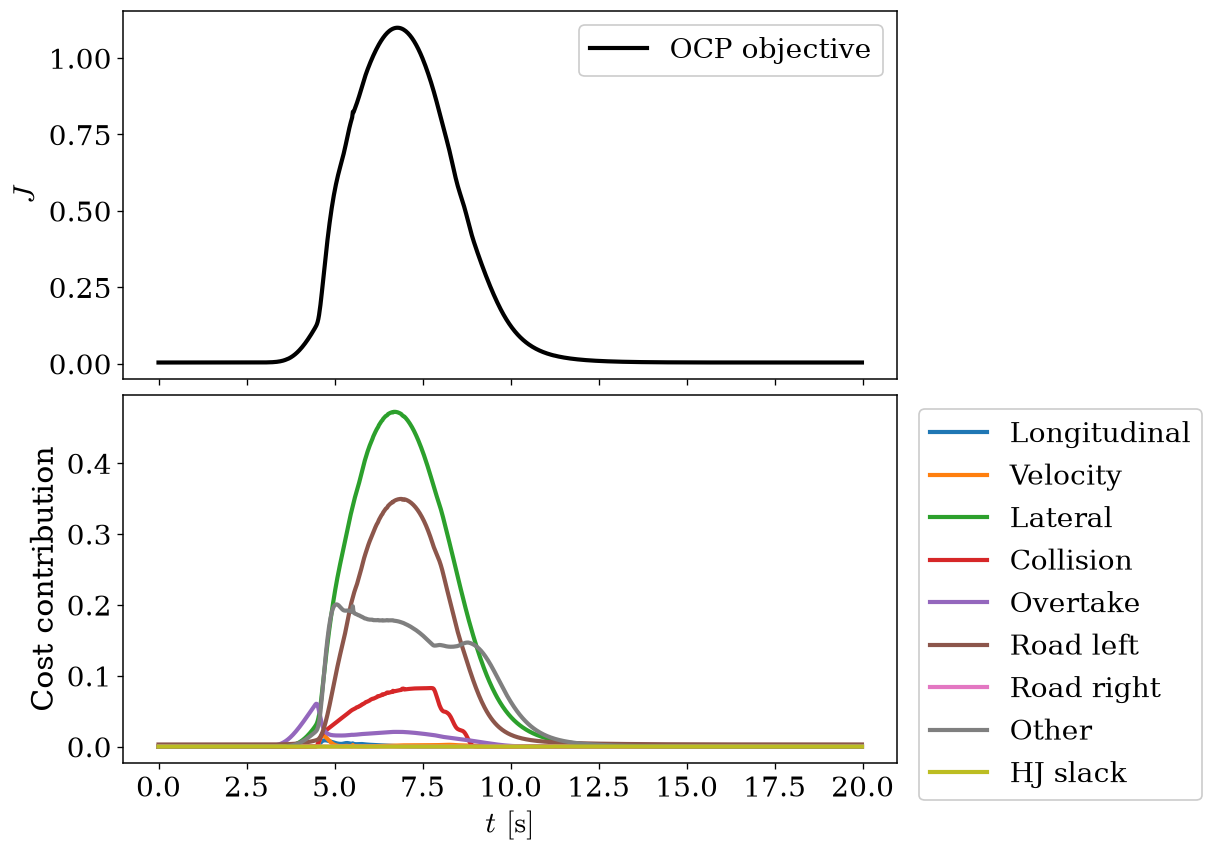

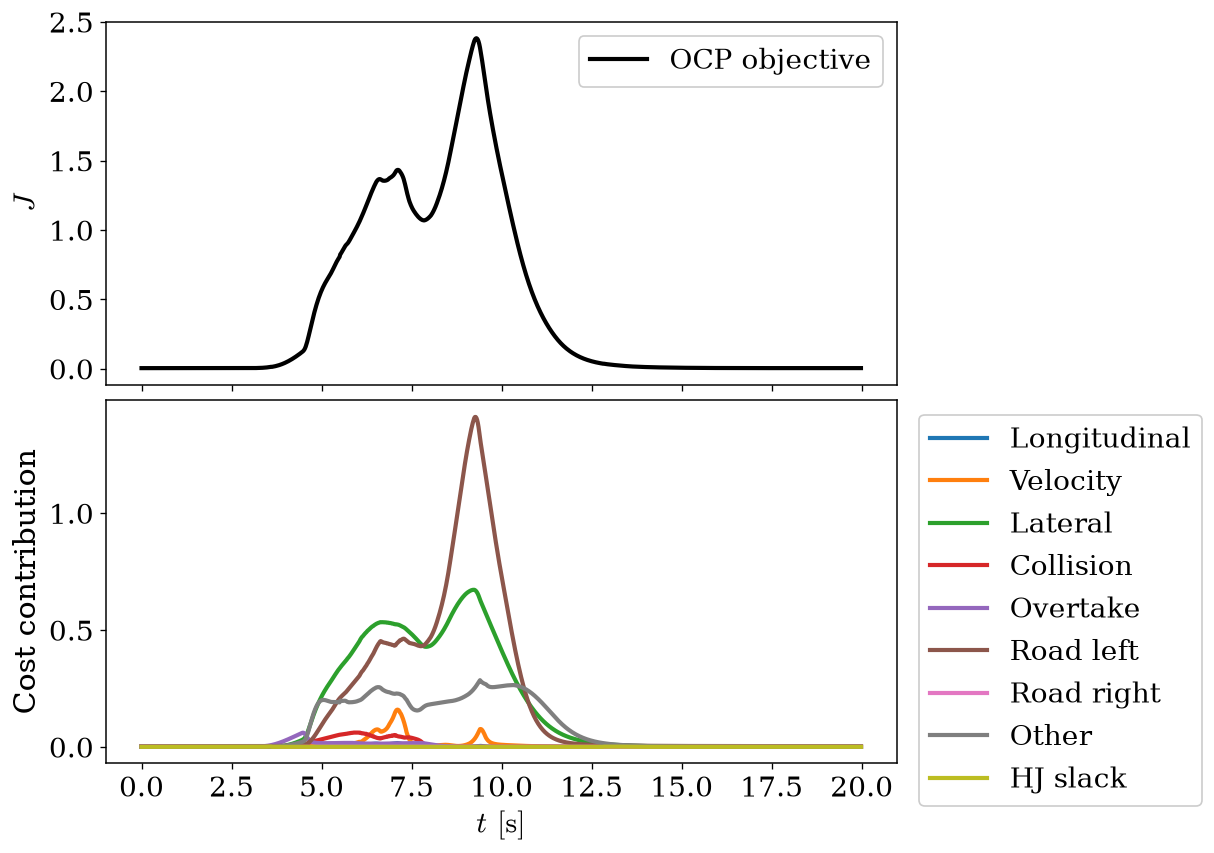

,run,max_abs_decomposition_error
0,multi_space,5.839412e-07
1,multi_time,3.140405e-07
2,multi_all,1.041800e-06


In [15]:
for run in runs:
    show(f"{run.name}_costs", plot_costs(run))

cost_checks = pd.DataFrame([cost_consistency(run) for run in runs])
display(cost_checks)


## Tempi di calcolo

Le statistiche usano tutti i campioni salvati, incluso il primo. Gli archivi correnti registrano il solo solver OCP: questi numeri non comprendono interpolazione HJ, aggiornamento dei parametri o ciclo completo del planner. Il confronto con il periodo di controllo è quindi parziale. Eventuali timer hj_time e controller_time verranno inclusi automaticamente nella tabella quando presenti. La macchina usata per il plotting non è quella su cui vengono misurati questi tempi.

,run,timer,samples,mean_ms,median_ms,p95_ms,p99_ms,max_ms,deadline_ms,within_deadline_pct,deadline_misses
0,multi_space,OCP solver,1000,108.742,12.504,256.025,498.224,597.147,20.0,52.8,472
1,multi_time,OCP solver,1000,110.775,93.262,230.145,391.274,432.039,20.0,46.3,537
2,multi_all,OCP solver,1000,123.762,13.532,299.989,589.876,720.462,20.0,55.2,448


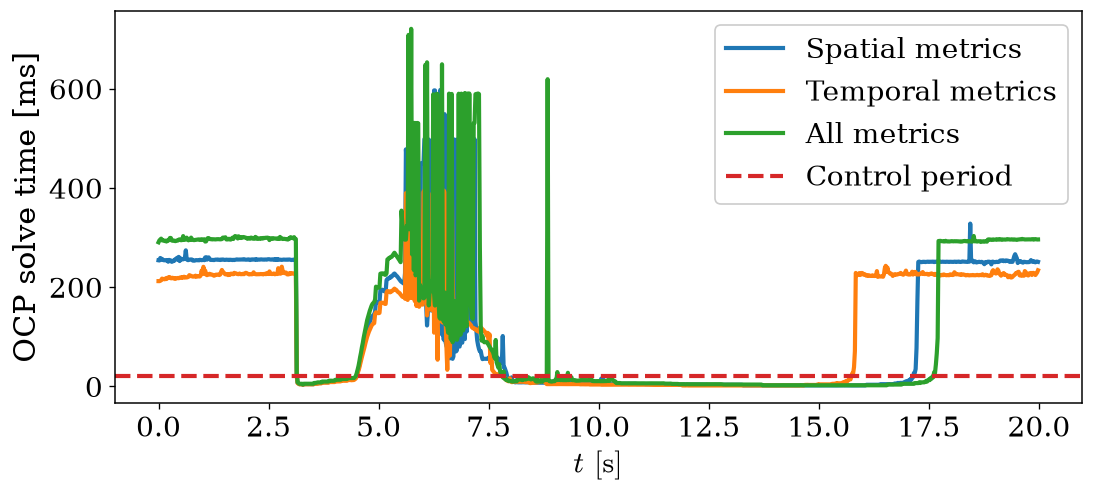

In [16]:
timing_table = timing_statistics(runs, CONTROL_FREQUENCY)
display(timing_table.round(3))
show("ocp_timings", plot_timings(runs, CONTROL_FREQUENCY))


## Esportazione

In [17]:
if EXPORT:
    exported = export_collection(
        figures, OUTPUT_GROUP, formats=FORMATS,
        tables={"timing_statistics": timing_table, "cost_consistency": cost_checks,
                "run_manifest": run_manifest(runs)},
    )
    print(f"Esportati {len(exported)} file in grafici/output/{OUTPUT_GROUP}")


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/multi_space_trajectory.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/multi_time_trajectory.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/multi_all_trajectory.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/multi_space_frames.pdf


... (24 outputs left out)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/multi_space_costs.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/multi_time_costs.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/multi_all_costs.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/multimetric/ocp_timings.pdf
Esportati 38 file in grafici/output/multimetric
